NumPy: 2.5.4
pandas: 3.1.0
Number of rows: 319
Number of columns: 39
Dataset shape: (319, 39)
Dataset datatypes:
Gallstone Status                                    int64
Age                                                 int64
Gender                                              int64
Comorbidity                                         int64
Coronary Artery Disease (CAD)                       int64
Hypothyroidism                                      int64
Hyperlipidemia                                      int64
Diabetes Mellitus (DM)                              int64
Height                                              int64
Weight                                            float64
Body Mass Index (BMI)                             float64
Total Body Water (TBW)                            float64
Extracellular Water (ECW)                         float64
Intracellular Water (ICW)                         float64
Extracellular Fluid/Total Body Water (ECF/TBW)    float64
Total Body Fat Ra

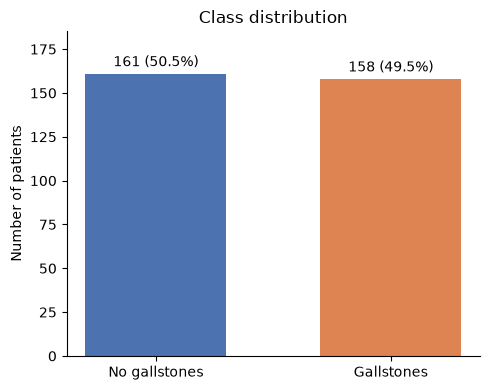

Gallstone Status  No gallstones  Gallstones
Gender                                     
Male                         94          68
Female                       67          90


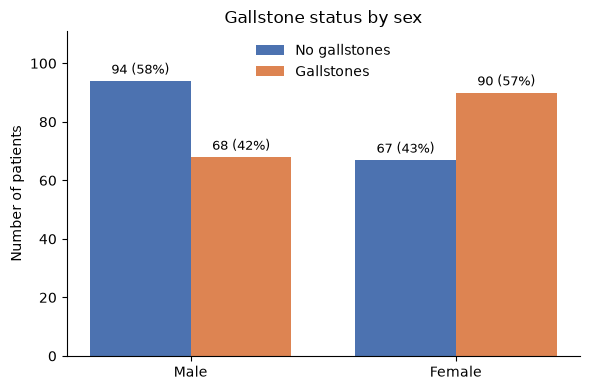

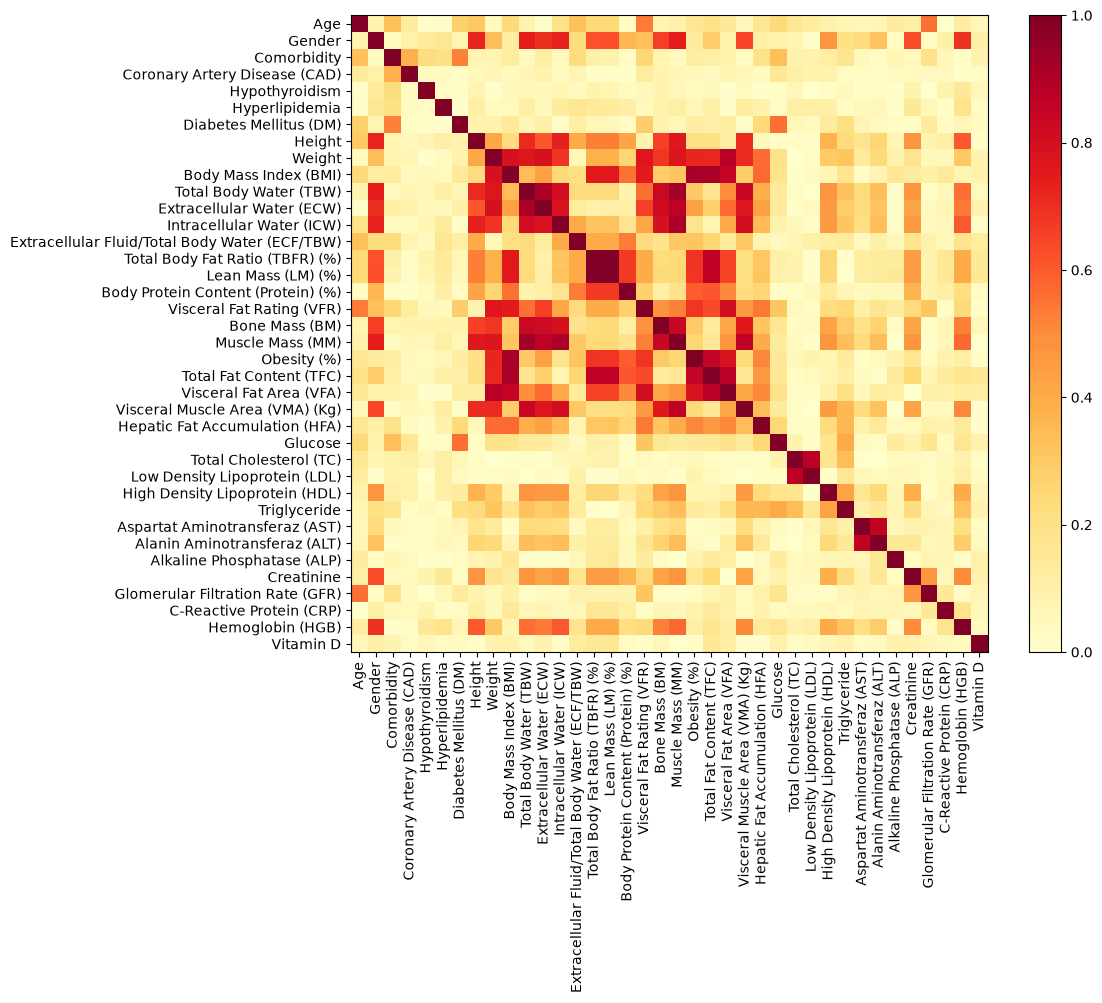

Dropped 5: ['Extracellular Water (ECW)', 'Lean Mass (LM) (%)', 'Muscle Mass (MM)', 'Obesity (%)', 'Total Fat Content (TFC)']
0      0
1      0
2      0
3      0
4      0
      ..
313    1
314    1
315    1
316    1
317    1
Name: Gallstone Status, Length: 317, dtype: int64


In [40]:
%run 1_data_exploration.ipynb
print (y)

# Model selection and training
Compares three models on the same split, CV scheme and metric (ROC AUC):
1. Logistic Regression
2. Logistic Regression + log features
3. XGBoost
4. Explainable Boosting Machine (EBM)

We want to test data based on simple logistic regression. However, We have skewed features (explained in cleaning) that are skewed at it's tail. So We are going to test it against Logistic with log  features. Using log should decrease skewness. (Result will uphold the theory). And a XG Boost model as these models do not depend on how skew the value is they are best models to test against Logistic models

Data cleaning and exploration are done in `1_`, validation in `3_`.

The EBM (from Microsoft's `interpret` library) is a *glass-box* boosting model: it learns one shape function per feature (plus a few pairwise interactions) and adds them up, so it can capture non-linear effects like XGBoost while staying as interpretable as logistic regression.

# Import dependencies

We are using sklearn to import logistic regression, and xgboost

In [41]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import (ParameterGrid, RepeatedStratifiedKFold,
                                     StratifiedKFold, cross_val_score,
                                     cross_validate, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from xgboost import XGBClassifier
from interpret.glassbox import ExplainableBoostingClassifier

print(f"NumPy: {np.__version__}")
print(f"pandas: {pd.__version__}")

NumPy: 2.5.4
pandas: 3.1.0


# Load dataset and split

We are dividing data set 80/20 rule, for training We are using 80 percent of data for training and 20 percent for testing.

In [42]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (253, 33), Test: (64, 33)


# Models and hyperparameter grids

Logistic Regression: C sets regularization strength
Logistic Regression + log: same C, but skewed features are first transformed with log1p before scaling.
XGBoost: We define number of trees, tree complexity learning rate 

EBM: `learning_rate` (step size of each boosting round), `interactions` (number of pairwise feature interactions, 0 = purely additive), `min_samples_leaf` (smoothness of the shape functions) and `max_bins` (how finely each continuous feature is binned). No scaling or log transform is needed, because the EBM bins every feature. The yes/no columns are declared *nominal* (categorical).

In [43]:
def make_model(name, **params):
    if name == "logreg":
        return make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=5000, **params),
        )
    if name == "logreg + log":
        return make_pipeline(
            ColumnTransformer([("log", FunctionTransformer(np.log1p), skewed)],
                              remainder="passthrough"),
            StandardScaler(),
            LogisticRegression(max_iter=5000, **params),
        )
    if name == "ebm":
        return ExplainableBoostingClassifier(feature_types=ebm_feature_types,
                                             random_state=42, **params)
    return XGBClassifier(eval_metric="logloss", random_state=42, **params)



# EBM: binary (yes/no) columns are categorical, everything else continuous
ebm_feature_types = ["nominal" if X[c].nunique() == 2 else "continuous" for c in X.columns]

C_grid = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
grids = {
    "logreg": {"C": C_grid},
    "logreg + log": {"C": C_grid},
"xgboost": {"max_depth": [3, 4],
            "learning_rate": [0.003, 0.01],
            "n_estimators": [30, 100, 300, 1000],},
"ebm": {"learning_rate": [0.01, 0.05],
        "interactions": [0, 5],
        "min_samples_leaf": [2, 8],
        "max_bins": [64, 256],},
}

# Tune with cross-validation (training set only)

using Cross-Validation before training.Cross-validation is a way to estimate how well a model will perform on unseen data by repeatedly training on part of the training set and validating on the part held out. We splitting in 5 equal parts

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
best_params = {}

for name, grid in grids.items():
    print(f"\n=== {name} ===")
    best_auc = -1
    for params in ParameterGrid(grid):
        scores = cross_validate(make_model(name, **params), X_train, y_train,
                                cv=cv, scoring=["accuracy", "roc_auc", "f1"])
        auc = scores["test_roc_auc"].mean()
        summary = "  ".join(
            f"{m}: {scores[f'test_{m}'].mean():.3f} ± {scores[f'test_{m}'].std():.3f}"
            for m in ["accuracy", "roc_auc", "f1"])
        print(f"{params}\n    {summary}")
        
        if auc > best_auc:
            best_auc, best_params[name] = auc, params
    print(f"Best (by CV ROC AUC): {best_params[name]} -> {best_auc:.3f}")


=== logreg ===
{'C': 0.001}
    accuracy: 0.664 ± 0.061  roc_auc: 0.743 ± 0.070  f1: 0.629 ± 0.084
{'C': 0.01}
    accuracy: 0.728 ± 0.064  roc_auc: 0.805 ± 0.081  f1: 0.708 ± 0.081
{'C': 0.1}
    accuracy: 0.763 ± 0.074  roc_auc: 0.845 ± 0.075  f1: 0.741 ± 0.094
{'C': 1}
    accuracy: 0.787 ± 0.044  roc_auc: 0.871 ± 0.053  f1: 0.775 ± 0.055
{'C': 10}
    accuracy: 0.807 ± 0.033  roc_auc: 0.877 ± 0.046  f1: 0.802 ± 0.034
{'C': 100}
    accuracy: 0.811 ± 0.028  roc_auc: 0.869 ± 0.049  f1: 0.806 ± 0.031
{'C': 1000}
    accuracy: 0.811 ± 0.028  roc_auc: 0.867 ± 0.050  f1: 0.806 ± 0.031
Best (by CV ROC AUC): {'C': 10} -> 0.877

=== logreg + log ===
{'C': 0.001}
    accuracy: 0.700 ± 0.077  roc_auc: 0.800 ± 0.067  f1: 0.656 ± 0.106
{'C': 0.01}
    accuracy: 0.787 ± 0.054  roc_auc: 0.870 ± 0.057  f1: 0.766 ± 0.067
{'C': 0.1}
    accuracy: 0.838 ± 0.055  roc_auc: 0.894 ± 0.060  f1: 0.826 ± 0.061
{'C': 1}
    accuracy: 0.819 ± 0.044  roc_auc: 0.892 ± 0.056  f1: 0.812 ± 0.051
{'C': 10}
    acc

,learning_rate,max_depth,n_estimators,ROC AUC mean,ROC AUC std,Accuracy mean,Accuracy std
15,0.010,4,1000,0.851,0.040,0.775,0.039
14,0.010,4,300,0.845,0.045,0.775,0.057
11,0.010,3,1000,0.844,0.049,0.767,0.051
7,0.003,4,1000,0.844,0.044,0.775,0.063
3,0.003,3,1000,0.839,0.059,0.767,0.068
10,0.010,3,300,0.839,0.059,0.767,0.068
2,0.003,3,300,0.823,0.063,0.747,0.055
9,0.010,3,100,0.822,0.066,0.751,0.057
6,0.003,4,300,0.815,0.050,0.763,0.068
13,0.010,4,100,0.814,0.049,0.763,0.063


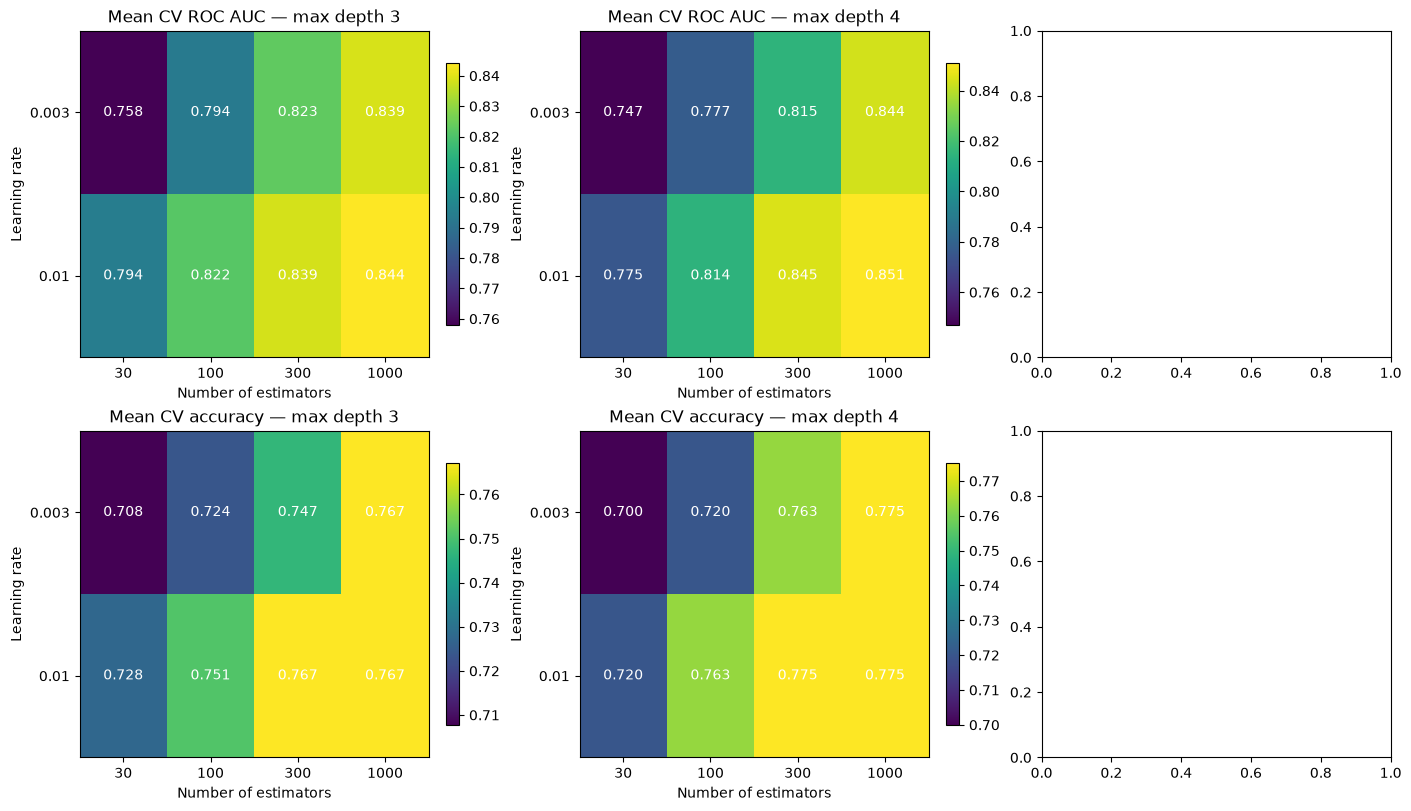

In [ ]:
from itertools import product

# ---------------- XGBoost (unchanged) ----------------
xgb_tuning_rows = []

for params in ParameterGrid(grids["xgboost"]):
    cv_scores = cross_validate(
        make_model("xgboost", **params),
        X_train,
        y_train,
        cv=cv,
        scoring=["roc_auc", "accuracy"],
    )
    xgb_tuning_rows.append({
        **params,
        "ROC AUC mean": cv_scores["test_roc_auc"].mean(),
        "ROC AUC std": cv_scores["test_roc_auc"].std(),
        "Accuracy mean": cv_scores["test_accuracy"].mean(),
        "Accuracy std": cv_scores["test_accuracy"].std(),
    })

xgb_tuning_results = pd.DataFrame(xgb_tuning_rows)

fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)

for row, (metric, title) in enumerate([
    ("ROC AUC mean", "Mean CV ROC AUC"),
    ("Accuracy mean", "Mean CV accuracy"),
]):
    for col, depth in enumerate(sorted(xgb_tuning_results["max_depth"].unique())):
        ax = axes[row, col]
        matrix = (
            xgb_tuning_results[xgb_tuning_results["max_depth"] == depth]
            .pivot(index="learning_rate", columns="n_estimators", values=metric)
            .sort_index()
        )

        image = ax.imshow(matrix.values, aspect="auto", cmap="viridis")
        ax.set_xticks(range(len(matrix.columns)), labels=matrix.columns)
        ax.set_yticks(range(len(matrix.index)), labels=matrix.index)
        ax.set_xlabel("Number of estimators")
        ax.set_ylabel("Learning rate")
        ax.set_title(f"{title} — max depth {depth}")

        for i in range(matrix.shape[0]):
            for j in range(matrix.shape[1]):
                ax.text(j, i, f"{matrix.iloc[i, j]:.3f}",
                        ha="center", va="center", color="white")

        fig.colorbar(image, ax=ax, shrink=0.8)

plt.show()


# ---------------- EBM (new) ----------------
ebm_tuning_rows = []

for params in ParameterGrid(grids["ebm"]):
    cv_scores = cross_validate(
        make_model("ebm", **params),
        X_train,
        y_train,
        cv=cv,
        scoring=["roc_auc", "accuracy"],
    )
    ebm_tuning_rows.append({
        **params,
        "ROC AUC mean": cv_scores["test_roc_auc"].mean(),
        "ROC AUC std": cv_scores["test_roc_auc"].std(),
        "Accuracy mean": cv_scores["test_accuracy"].mean(),
        "Accuracy std": cv_scores["test_accuracy"].std(),
    })

ebm_tuning_results = pd.DataFrame(ebm_tuning_rows)

# One panel per (min_samples_leaf, max_bins) combination
panel_keys = list(product(
    sorted(ebm_tuning_results["min_samples_leaf"].unique()),
    sorted(ebm_tuning_results["max_bins"].unique()),
))

fig, axes = plt.subplots(2, len(panel_keys), figsize=(18, 8), constrained_layout=True)

for row, (metric, title) in enumerate([
    ("ROC AUC mean", "Mean CV ROC AUC"),
    ("Accuracy mean", "Mean CV accuracy"),
]):
    for col, (leaf, bins) in enumerate(panel_keys):
        ax = axes[row, col]
        matrix = (
            ebm_tuning_results[
                (ebm_tuning_results["min_samples_leaf"] == leaf)
                & (ebm_tuning_results["max_bins"] == bins)
            ]
            .pivot(index="learning_rate", columns="interactions", values=metric)
            .sort_index()
        )

        image = ax.imshow(matrix.values, aspect="auto", cmap="viridis")
        ax.set_xticks(range(len(matrix.columns)), labels=matrix.columns)
        ax.set_yticks(range(len(matrix.index)), labels=matrix.index)
        ax.set_xlabel("Interactions")
        ax.set_ylabel("Learning rate")
        ax.set_title(f"{title}\nmin leaf {leaf}, max bins {bins}")

        for i in range(matrix.shape[0]):
            for j in range(matrix.shape[1]):
                ax.text(j, i, f"{matrix.iloc[i, j]:.3f}",
                        ha="center", va="center", color="white")

        fig.colorbar(image, ax=ax, shrink=0.8)

plt.show()

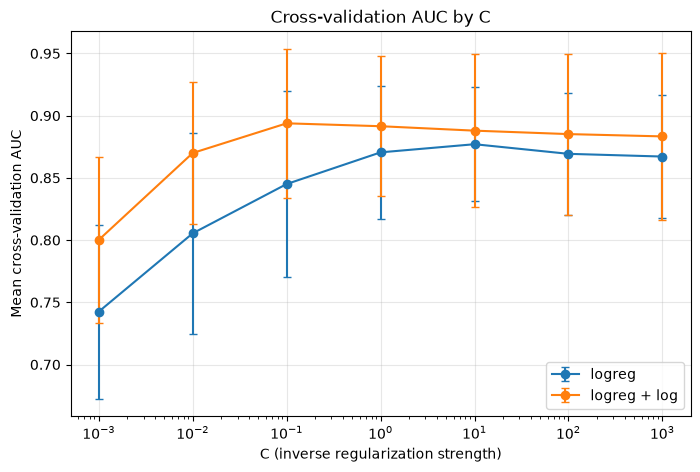

In [ ]:
import matplotlib.pyplot as plt

cv_accuracy = {}

for name in ["logreg", "logreg + log"]:
    means, stds = [], []
    for C in C_grid:
        scores = cross_val_score(
            make_model(name, C=C),
            X_train,
            y_train,
            cv=cv,
            scoring="roc_auc",
        )
        means.append(scores.mean())
        stds.append(scores.std())
    cv_accuracy[name] = (means, stds)

fig, ax = plt.subplots(figsize=(8, 5))
for name, (means, stds) in cv_accuracy.items():
    ax.errorbar(C_grid, means, yerr=stds, marker="o", capsize=3, label=name)

ax.set_xscale("log")
ax.set_xlabel("C (inverse regularization strength)")
ax.set_ylabel("Mean cross-validation AUC")
ax.set_title("Cross-validation AUC by C")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()